Adam Error (MSE): 0.21785692059503858


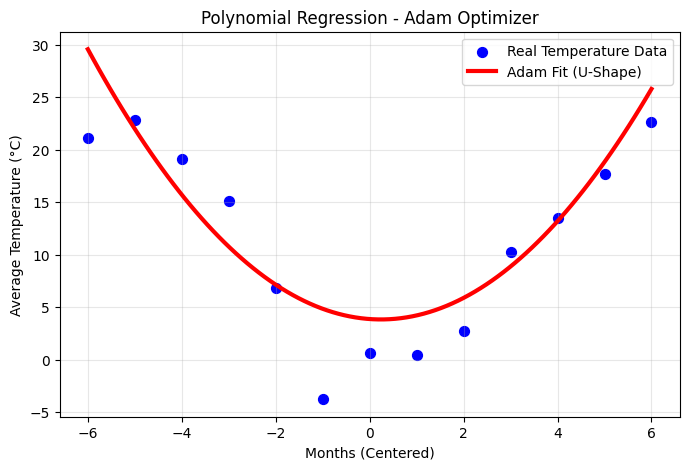

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error

df = pd.read_csv('/kaggle/input/datasets/berkeleyearth/climate-change-earth-surface-temperature-data/GlobalLandTemperaturesByMajorCity.csv')
df = df.dropna()
df_city = df[(df['City'] == 'Chicago') & (df['dt'] >= '2000-07-01') & (df['dt'] <= '2001-07-01')]

X = np.arange(len(df_city)).reshape(-1, 1)
y = df_city['AverageTemperature'].values
X_centered = X - np.mean(X)

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X_centered)

scaler_X = StandardScaler()
X_poly_scaled = scaler_X.fit_transform(X_poly)
scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()


adam = MLPRegressor(hidden_layer_sizes=(), activation='identity', solver='adam', max_iter=5000, random_state=42)
adam.fit(X_poly_scaled, y_scaled)
mse = mean_squared_error(y_scaled, adam.predict(X_poly_scaled))
print("Adam Error (MSE):", mse)

plt.figure(figsize=(8, 5))
plt.scatter(X_centered, y, color='blue', s=50, label='Real Temperature Data')
X_grid = np.linspace(min(X_centered), max(X_centered), 100).reshape(-1, 1)
X_grid_poly = poly.transform(X_grid)
X_grid_poly_scaled = scaler_X.transform(X_grid_poly)
y_pred_scaled = adam.predict(X_grid_poly_scaled)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))
plt.plot(X_grid, y_pred, color='red', linewidth=3, label='Adam Fit (U-Shape)')
plt.xlabel('Months (Centered)')
plt.ylabel('Average Temperature (°C)')
plt.title('Polynomial Regression - Adam Optimizer')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


--- Logistic Regression (Adam) Metrics ---
Log Loss  : 0.2785
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


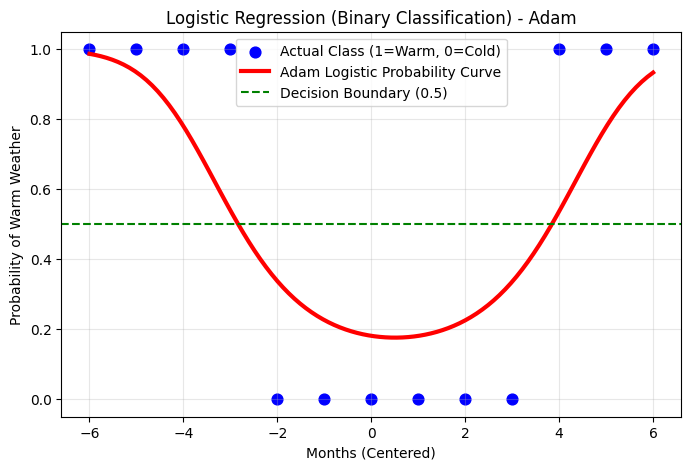

In [2]:
# ==========================================
# Assignment 2: Logistic Regression (Adam)
# ==========================================
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

# 1. تحويل درجات الحرارة إلى تصنيف ثنائي (1 = حار، 0 = بارد)
threshold = np.mean(y)
y_binary = (y > threshold).astype(int)

# 2. بناء وتدريب موديل Logistic Regression باستخدام Adam Optimizer
adam_clf = MLPClassifier(hidden_layer_sizes=(), solver='adam', max_iter=5000, random_state=42)
adam_clf.fit(X_poly_scaled, y_binary)

# 3. التوقع وحساب الاحتمالات
y_pred_class = adam_clf.predict(X_poly_scaled)
y_pred_prob = adam_clf.predict_proba(X_poly_scaled)[:, 1]

# 4. حساب وطباعة المقاييس الخمسة المطلوبة
acc = accuracy_score(y_binary, y_pred_class)
prec = precision_score(y_binary, y_pred_class)
rec = recall_score(y_binary, y_pred_class)
f1 = f1_score(y_binary, y_pred_class)
loss = log_loss(y_binary, y_pred_prob)

print("--- Logistic Regression (Adam) Metrics ---")
print(f"Log Loss  : {loss:.4f}")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")

# 5. رسم منحنى الاحتمالات
plt.figure(figsize=(8, 5))
plt.scatter(X_centered, y_binary, color='blue', s=60, label='Actual Class (1=Warm, 0=Cold)')

X_grid = np.linspace(min(X_centered), max(X_centered), 100).reshape(-1, 1)
X_grid_poly = poly.transform(X_grid)
X_grid_poly_scaled = scaler_X.transform(X_grid_poly)
y_grid_prob = adam_clf.predict_proba(X_grid_poly_scaled)[:, 1]

plt.plot(X_grid, y_grid_prob, color='red', linewidth=3, label='Adam Logistic Probability Curve')
plt.axhline(0.5, color='green', linestyle='--', label='Decision Boundary (0.5)')
plt.xlabel('Months (Centered)')
plt.ylabel('Probability of Warm Weather')
plt.title('Logistic Regression (Binary Classification) - Adam')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


--- Random Forest + Adam Metrics ---
Log Loss  : 0.1706
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


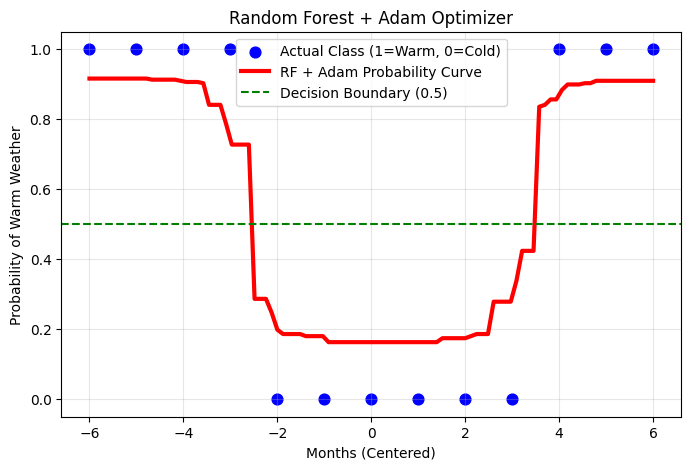

In [3]:
# ==========================================
# Assignment 3: Random Forest + Adam
# ==========================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

y_binary = (y > np.mean(y)).astype(int)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_poly_scaled, y_binary)
rf_features = rf.predict_proba(X_poly_scaled)

adam_rf = MLPClassifier(hidden_layer_sizes=(), solver='adam', max_iter=5000, random_state=42)
adam_rf.fit(rf_features, y_binary)

y_pred = adam_rf.predict(rf_features)
y_prob = adam_rf.predict_proba(rf_features)[:, 1]

print("--- Random Forest + Adam Metrics ---")
print(f"Log Loss  : {log_loss(y_binary, y_prob):.4f}")
print(f"Accuracy  : {accuracy_score(y_binary, y_pred):.4f}")
print(f"Precision : {precision_score(y_binary, y_pred):.4f}")
print(f"Recall    : {recall_score(y_binary, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_binary, y_pred):.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_centered, y_binary, color='blue', s=60, label='Actual Class (1=Warm, 0=Cold)')
X_grid = np.linspace(min(X_centered), max(X_centered), 100).reshape(-1, 1)
X_grid_scaled = scaler_X.transform(poly.transform(X_grid))
y_grid_prob = adam_rf.predict_proba(rf.predict_proba(X_grid_scaled))[:, 1]
plt.plot(X_grid, y_grid_prob, color='red', linewidth=3, label='RF + Adam Probability Curve')
plt.axhline(0.5, color='green', linestyle='--', label='Decision Boundary (0.5)')
plt.xlabel('Months (Centered)')
plt.ylabel('Probability of Warm Weather')
plt.title('Random Forest + Adam Optimizer')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
